# Nested Clustered Optimization

*Does splitting a portfolio into groups before optimizing (NCO) protect it from estimation error?*

**Short answer.** When the true risk of every asset is known and only the estimates are noisy, grouping first works well. Minimum-variance portfolios end 7% above the lowest achievable risk instead of 22%, and max-Sharpe portfolios reach 67% of the best achievable Sharpe ratio instead of 43%. In real long-only portfolios most of that gain disappears: NCO adds 0.02 to 0.03 to the Sharpe ratio, inside the range of noise, and it trades more because its groups change from month to month. Simple allocators (equal weight, inverse variance, risk parity) beat every optimizer on the ETFs.

| Question | Finding | Section |
|---|---|---|
| Do the allocators agree in the simplest case? | With unrelated assets, risk parity, inverse variance and minimum variance give the same weights (0.59, 0.26, 0.15). | 1 |
| How much risk does estimation error add? | With 40 assets and 10 years of monthly data, plain minimum variance ends 22% above the lowest achievable risk; NCO 7%; a cleaned (denoised) covariance 8%. | 2 |
| Does NCO protect a max-Sharpe portfolio? | Yes. Plain max-Sharpe reaches 43% of the best achievable Sharpe ratio on average, NCO 67%. | 2 |
| Why does NCO help? | Each step solves a smaller, more stable problem: error amplification falls from 132 to at most 35, and one extra month of data moves the weights a third as much (0.031 vs 0.106). | 3 |
| Does the gain survive on real long-only portfolios? | Barely. On 22 ETFs, NCO lifts the minimum-variance Sharpe ratio from 0.47 to 0.49 and max-Sharpe from 0.52 to 0.53. On 112 ETFs and stocks, 0.47 to 0.49 and 1.09 to 1.13. Equal weight leads on the ETFs at 0.79. | 4 |
| Is any real-data difference larger than noise? | No. All six 90% intervals for the Sharpe difference include zero (for example NCO-MinVar on ETFs −0.03 to +0.07, on 112 assets −0.08 to +0.13). | 4.1 |
| What does each method cost in concentration and trading? | Minimum-variance portfolios hold about 2 effective positions, with 61–73% in the largest. NCO trades more than the plain optimizer (on 112 assets 0.133 vs 0.049 per rebalance), which turns its minimum-variance edge negative after costs (0.43 vs 0.44). | 5 |

**Why it matters.** An optimizer treats every estimated number as exact. With 40 assets it needs 40 volatilities and 780 correlations, estimated from a few years of data. It then puts the most weight on assets whose risk happens to look low in that sample, so a small error in one estimate spreads into every weight. A portfolio that looks safest on paper can be riskier in practice than a simple equal split.

**Approach.**
1. Check the allocators on a case with a known answer.
2. Simulate a market whose true risks are known, estimate them from noisy samples, and score each allocator against the truth.
3. Measure why grouping helps: error amplification and how much weights move with new data.
4. Run monthly long-only backtests on 22 ETFs and on 112 ETFs and stocks, with bootstrap intervals for the differences.
5. Compare risk, concentration and trading costs.

**The allocators.** *Equal weight*: 1/N in each asset. *Inverse variance*: more weight on calmer assets, correlations ignored. *Minimum variance*: the mix with the lowest estimated risk. *Max-Sharpe*: the mix with the highest estimated return per unit of risk. *Hierarchical risk parity (HRP)*: sorts assets into a tree by correlation and splits risk evenly down the branches, without inverting the covariance matrix. *NCO*: groups assets by correlation, optimizes inside each group, treats each group as one asset, then optimizes across groups.

**Use it when.** Allocating across many assets with a monthly or quarterly rebalance, especially for objectives that lean on noisy return estimates (max-Sharpe, long-short, leverage).

**Data.** Daily adjusted closes, Jan 2015 to Oct 2026 (Yahoo Finance): 22 multi-asset ETFs and 90 US large-cap stocks (112 together). The short-term Treasury fund SHY is excluded (section 4). Backtests start Jan 2017 with a two-year (504-day) look-back, rebalance every 21 trading days (about monthly) and hold no short positions. The stock list holds today's large caps (survivorship bias), so stock results compare allocators rather than show achievable returns.

**Contents.** 1 The allocators · 2 Estimation error with a known answer · 3 Why grouping helps · 4 Real backtests · 5 Risk, concentration and cost · Conclusions

In [1]:
import sys, warnings
sys.path.insert(0, ".")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import data_utils as du
import quant_tools as qt

du.set_style()
etf = du.load_returns("etfs", log=False)
stk = du.load_returns("stocks", log=False)
both = pd.concat([etf, stk], axis=1)
print(f"ETFs {etf.shape[1]} (incl. SHY, dropped later), stocks {stk.shape[1]}, {both.index[0].date()} to {both.index[-1].date()}")

ETFs 23 (incl. SHY, dropped later), stocks 90, 2015-01-05 to 2026-10-30


## 1 · The allocators

Every allocator takes a covariance matrix Σ, which holds each asset's variance and every pair's covariance, and returns weights that sum to 1. Max-Sharpe also takes expected returns μ.
- **Equal weight (EW)**: 1/N in each asset. Uses no estimates at all.
- **Inverse variance (IVP)**: weight proportional to 1/σ². Uses volatilities and ignores correlations.
- **Minimum variance (MVO)**: weights proportional to Σ⁻¹·1 (with short positions allowed), or the long-only version solved numerically. Uses the whole matrix, including its inverse.
- **Hierarchical risk parity (HRP)**: order assets by a correlation tree, then split risk top-down between the two halves of each branch. Never inverts Σ.
- **NCO**: (1) group the assets by correlation; (2) optimize inside each group; (3) treat each group as one combined asset and optimize across groups; (4) final weight = weight inside the group × weight of the group. Any optimizer can be used at steps 2 and 3.

A useful picture for NCO: a company sets a budget for each department and lets each department split its own budget. Each decision uses a few numbers that are well understood, rather than one decision that uses all of them at once.

A simple first check: with three unrelated assets (volatilities 20%, 30% and 40%), HRP, inverse variance and minimum variance should give identical weights, because without correlations all three reduce to 1/σ².

In [2]:
def ew_weights(cov):
    n = len(cov)
    return np.ones(n) / n

def ivp_weights(cov):
    w = 1 / np.diag(cov)
    return w / w.sum()

def hrp_weights(cov):
    cov = np.asarray(cov)
    std = np.sqrt(np.diag(cov))
    corr = cov / np.outer(std, std)
    dist = np.sqrt(np.clip((1 - corr) / 2, 0, None))
    np.fill_diagonal(dist, 0)
    order = list(leaves_list(linkage(squareform(dist, checks=False), "single")))
    w = pd.Series(1.0, index=order)
    stack = [order]
    while stack:
        items = stack.pop()
        if len(items) <= 1:
            continue
        half = len(items) // 2
        left, right = items[:half], items[half:]
        def cvar(ix):
            sub = cov[np.ix_(ix, ix)]
            iv = 1 / np.diag(sub)
            iv /= iv.sum()
            return iv @ sub @ iv
        vl, vr = cvar(left), cvar(right)
        alpha = 1 - vl / (vl + vr)
        w[left] *= alpha
        w[right] *= 1 - alpha
        stack += [left, right]
    return w.sort_index().values

# tiny check: three assets, uncorrelated -> HRP = inverse variance; MVO closed form = inverse variance too
c3 = np.diag([0.04, 0.09, 0.16])
print("uncorrelated: HRP", hrp_weights(c3).round(3), "IVP", ivp_weights(c3).round(3), "MVO", qt.min_var_weights(c3).round(3))

uncorrelated: HRP [0.59  0.262 0.148] IVP [0.59  0.262 0.148] MVO [0.59  0.262 0.148]


- All three rules give 0.59, 0.26 and 0.15, the inverse-variance weights. The building blocks agree before they meet correlated data.

## 2 · How much does estimation error cost when the truth is known?

On real data the true risk of a portfolio is never known, so estimation error cannot be measured there. A simulated market solves this:
- **40 assets in 5 groups of 8.** Assets in the same group have correlation 0.5; assets in different groups 0.1.
- **Monthly volatilities between 5% and 12%**, and expected returns of 0.15 × volatility, so every asset has the same Sharpe ratio (about 0.5 a year). The Sharpe ratio is return per unit of risk.
- **200 samples of 120 months each** (10 years, three observations per asset). From each sample Σ and μ are estimated, weights are built, and the weights are scored with the **true** Σ and μ.

Two scores:
- **Minimum variance**: the portfolio's true volatility divided by the lowest achievable (1.00 = perfect, 1.22 = 22% riskier than necessary).
- **Max-Sharpe**: the portfolio's true Sharpe ratio divided by the best achievable (1.00 = perfect).

NCO is run with groups found by the clustering method ONC (optimal number of clusters, which also picks the number of groups) and with the true groups as an upper bound. A cleaned covariance (denoised: eigenvalues that look like pure noise are flattened) is a second cure for comparison. One more thing is recorded: the share of samples where the plain max-Sharpe weights flip sign. This happens when the unconstrained weights Σ⁻¹μ sum to a negative number, and scaling them to sum to 1 turns the best portfolio into its opposite.

Optimal minimum volatility 0.0263 per month; optimal Sharpe (per month) 0.342; ONC clusters found: mean 5.1 (truth 5)
Draws where plain max-Sharpe scaling flips sign: 0.5%; MVO mean Sharpe ratio excluding them: 0.429

Minimum-variance objective
              true vol / optimal (mean)  worst draw  weight RMSE vs optimal
MVO                               1.222       1.389                   0.049
MVO denoised                      1.081       1.176                   0.028
NCO (ONC)                         1.073       1.131                   0.025
NCO (oracle)                      1.072       1.131                   0.025
HRP                               1.286       1.328                   0.048
IVP                               1.278       1.292                   0.048
EW                                1.423       1.423                   0.060

Max-Sharpe objective
              true Sharpe / optimal (mean)  median  worst draw
MVO                                  0.426   0.434      -0.197

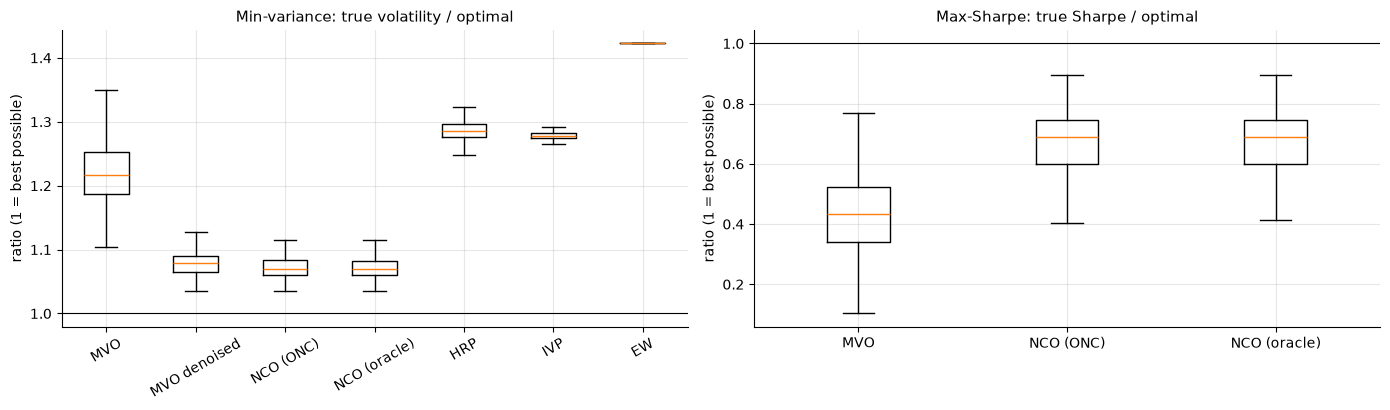

In [3]:
rng = np.random.default_rng(21)
N_BLOCKS, BLOCK = 5, 8
N = N_BLOCKS * BLOCK
true_block = np.repeat(np.arange(N_BLOCKS), BLOCK)
true_corr = np.where(true_block[:, None] == true_block[None, :], 0.5, 0.1)
np.fill_diagonal(true_corr, 1.0)
vols = rng.uniform(0.05, 0.12, N)
true_cov = true_corr * np.outer(vols, vols)
true_mu = 0.15 * vols
cols = [f"a{i}" for i in range(N)]

w_mv_opt = qt.min_var_weights(true_cov)
vol_opt = np.sqrt(w_mv_opt @ true_cov @ w_mv_opt)
w_ms_opt = qt.max_sharpe_weights(true_cov, true_mu)
sr_opt = (w_ms_opt @ true_mu) / np.sqrt(w_ms_opt @ true_cov @ w_ms_opt)

def sharpe_of(w):
    return (w @ true_mu) / np.sqrt(w @ true_cov @ w)

res_mv = {k: [] for k in ["MVO", "MVO denoised", "NCO (ONC)", "NCO (oracle)", "HRP", "IVP", "EW"]}
res_ms = {k: [] for k in ["MVO", "NCO (ONC)", "NCO (oracle)"]}
rmse = {k: [] for k in res_mv}
k_found, sign_flip = [], []
for rep in range(200):
    x = rng.multivariate_normal(true_mu, true_cov, size=120)
    cov = pd.DataFrame(np.cov(x, rowvar=False), index=cols, columns=cols)
    mu = pd.Series(x.mean(axis=0), index=cols)
    corr_hat = pd.DataFrame(qt.cov2corr(cov.values), index=cols, columns=cols)
    lab, _ = qt.onc(corr_hat, max_k=10, n_init=5, refine_single=True)
    k_found.append(lab.nunique())
    oracle = pd.Series(true_block, index=cols)
    cd, _ = qt.denoise_corr(corr_hat.values, 120 / N)
    cov_dn = pd.DataFrame(qt.corr2cov(cd, np.sqrt(np.diag(cov))), index=cols, columns=cols)
    w = {
        "MVO": qt.min_var_weights(cov.values),
        "MVO denoised": qt.min_var_weights(cov_dn.values),
        "NCO (ONC)": qt.nco_weights(cov, lab).values,
        "NCO (oracle)": qt.nco_weights(cov, oracle).values,
        "HRP": hrp_weights(cov.values),
        "IVP": ivp_weights(cov.values),
        "EW": ew_weights(cov.values),
    }
    for k, wk in w.items():
        res_mv[k].append(np.sqrt(wk @ true_cov @ wk) / vol_opt)
        rmse[k].append(np.sqrt(np.mean((wk - w_mv_opt) ** 2)))
    ms = {
        "MVO": qt.max_sharpe_weights(cov.values, mu.values),
        "NCO (ONC)": qt.nco_weights(cov, lab, qt.max_sharpe_weights, mu).values,
        "NCO (oracle)": qt.nco_weights(cov, oracle, qt.max_sharpe_weights, mu).values,
    }
    for k, wk in ms.items():
        res_ms[k].append(sharpe_of(wk) / sr_opt)
    sign_flip.append(not qt.tangency_sign_ok(cov.values, mu.values))

tab_mv = pd.DataFrame({"true vol / optimal (mean)": {k: np.mean(v) for k, v in res_mv.items()},
                       "worst draw": {k: np.max(v) for k, v in res_mv.items()},
                       "weight RMSE vs optimal": {k: np.mean(v) for k, v in rmse.items()}})
tab_ms = pd.DataFrame({"true Sharpe / optimal (mean)": {k: np.mean(v) for k, v in res_ms.items()},
                       "median": {k: np.median(v) for k, v in res_ms.items()},
                       "worst draw": {k: np.min(v) for k, v in res_ms.items()}})
print(f"Optimal minimum volatility {vol_opt:.4f} per month; optimal Sharpe (per month) {sr_opt:.3f}; ONC clusters found: mean {np.mean(k_found):.1f} (truth 5)")
print(f"Draws where plain max-Sharpe scaling flips sign: {np.mean(sign_flip):.1%}; MVO mean Sharpe ratio excluding them: {np.mean(np.array(res_ms['MVO'])[~np.array(sign_flip)]):.3f}")
print("\nMinimum-variance objective"); print(tab_mv.round(3).to_string())
print("\nMax-Sharpe objective"); print(tab_ms.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].boxplot([res_mv[k] for k in res_mv], tick_labels=list(res_mv), showfliers=False)
axes[0].axhline(1, color="k", lw=0.8)
axes[0].set(title="Min-variance: true volatility / optimal", ylabel="ratio (1 = best possible)"); axes[0].tick_params(axis="x", rotation=30)
axes[1].boxplot([res_ms[k] for k in res_ms], tick_labels=list(res_ms), showfliers=False)
axes[1].axhline(1, color="k", lw=0.8)
axes[1].set(title="Max-Sharpe: true Sharpe / optimal", ylabel="ratio (1 = best possible)")
plt.tight_layout(); plt.show()

- ONC finds 5.1 groups on average (truth: 5), so NCO with estimated groups performs like NCO with the true groups. Equal-sized, well-separated groups are the easy case for clustering.
- Minimum variance: the plain optimizer ends 22% above the lowest achievable volatility on average (39% in the worst sample). NCO cuts the excess to 7% (13% worst), and the denoised covariance to 8% (18% worst). With grouped truth the two cures are comparable.
- HRP and inverse variance are stable but 28–29% above the lowest risk, because they use only part of the correlation information. Equal weight is 42% above.
- Distance from the best weights (root mean squared error): 0.049 for plain MVO, 0.025 for NCO, 0.028 denoised, 0.048 for HRP and inverse variance, 0.060 for equal weight.
- Max-Sharpe is where noisy estimates hurt most, because expected returns are much harder to estimate than risks. The plain optimizer reaches 43% of the best Sharpe ratio on average, NCO 67% (worst sample 32%).
- The plain optimizer's single negative sample (−0.20) is the sign flip described above, in 0.5% of samples. Without it the plain average is still 43%, so NCO's gain comes from keeping estimation error inside each group, not from avoiding that one failure.
- When the objective uses expected returns, grouping first recovers about half of what estimation error destroys.

## 3 · Why does grouping help?

Minimum variance needs the inverse of Σ. Inverting a matrix amplifies errors in it, and the **condition number** measures by how much: the ratio of the largest to the smallest eigenvalue. A condition number of 1 means no amplification; 132 means small errors in the estimates can grow up to 132-fold in the weights. Large matrices estimated from few observations have high condition numbers.

NCO never inverts the full matrix. It inverts one small matrix per group and one small matrix across groups. Two measurements on one simulated sample:
- the condition number of the full matrix against the largest one NCO inverts;
- **turnover caused by one extra month of data**: how much the weights move (half the sum of absolute weight changes) when the 120-month window slides by one month. A stable method moves little, because one month barely changes what is known.

In [4]:
x_all = rng.multivariate_normal(true_mu, true_cov, size=121)
cov_a = pd.DataFrame(np.cov(x_all[:120], rowvar=False), index=cols, columns=cols)
cov_b = pd.DataFrame(np.cov(x_all[1:], rowvar=False), index=cols, columns=cols)
oracle = pd.Series(true_block, index=cols)

def cond_nco(cov, labels):
    conds = [np.linalg.cond(cov.loc[labels.index[labels == c], labels.index[labels == c]].values) for c in sorted(labels.unique())]
    intra = pd.DataFrame(0.0, index=cov.index, columns=sorted(labels.unique()))
    for c in intra:
        m = labels.index[labels == c]
        intra.loc[m, c] = qt.min_var_weights(cov.loc[m, m].values)
    cov_r = intra.T.values @ cov.values @ intra.values
    return np.max(conds), np.linalg.cond(cov_r)

mx_intra, c_inter = cond_nco(cov_a, oracle)
print(f"condition number: full matrix {np.linalg.cond(cov_a.values):.0f}; largest within-cluster {mx_intra:.0f}; across-cluster {c_inter:.0f}")
shift = {"MVO": 0.5 * np.abs(qt.min_var_weights(cov_a.values) - qt.min_var_weights(cov_b.values)).sum(),
         "NCO (oracle)": 0.5 * np.abs(qt.nco_weights(cov_a, oracle).values - qt.nco_weights(cov_b, oracle).values).sum(),
         "HRP": 0.5 * np.abs(hrp_weights(cov_a.values) - hrp_weights(cov_b.values)).sum()}
print("turnover caused by one extra month of data:", {k: round(float(v), 3) for k, v in shift.items()})

condition number: full matrix 132; largest within-cluster 35; across-cluster 2
turnover caused by one extra month of data: {'MVO': 0.106, 'NCO (oracle)': 0.031, 'HRP': 0.101}


- The full matrix has a condition number of 132. The largest matrix NCO inverts has 35, and the across-group matrix 2. Every step NCO takes is a much more stable problem.
- One extra month moves plain MVO weights by 0.106 (10.6% of the portfolio traded) and HRP by 0.101, but NCO by 0.031, about a third.
- Less reaction to noise means fewer trades for the same information, and lower trading costs.

## 4 · Does the gain survive on real portfolios?

Two universes:
- **22 multi-asset ETFs**: US and international equity, bonds, credit, real estate and commodities. SHY (a 1–3 year Treasury fund with about 1% volatility) is dropped, because a near-cash asset would absorb almost all of any minimum-variance portfolio.
- **112 assets**: the 22 ETFs plus 90 US large-cap stocks.

At each rebalance, Σ and μ are estimated from the previous 504 trading days (two years), weights are built, and they are held for the next 21 trading days. No short positions are allowed. Allocators compared:
- Equal weight, inverse variance, HRP;
- **MinVar**: long-only minimum variance on the sample covariance;
- **NCO-MinVar (ONC)**: groups found by ONC on the correlation matrix after removing the common market factor (detoning), minimum variance inside and across groups;
- **NCO-MinVar (k = 8)**: the same with a fixed 8 groups from k-means, to check whether the automatic group count matters;
- **MaxSharpe**: long-only max-Sharpe with the trailing two-year average return as μ. This is deliberately noisy, the case where estimation error hurts most;
- **NCO-MaxSharpe (ONC)**: the same optimizer inside NCO.

Reported for each: annualised return, volatility and Sharpe ratio; maximum drawdown (the largest peak-to-trough fall); average turnover (half the sum of weight changes per rebalance); effective number of holdings (1/Σw², the number of equal-sized positions the portfolio is equivalent to); the average largest weight; and the Sharpe ratio after a trading cost of 10 basis points (0.10%) per unit traded.

In [5]:
LOOKBACK, HOLD = 504, 21
COST = 0.0010
etf = etf.drop(columns=["SHY"])
both = pd.concat([etf, stk], axis=1)

def cluster_labels(window, kind):
    corr = window.corr()
    if kind == "onc":
        c = pd.DataFrame(qt.detone_corr(corr.values, 1), index=corr.index, columns=corr.columns)
        lab, _ = qt.onc(c, max_k=15, n_init=3, refine_single=True)
        return lab
    dist = ((1 - corr) / 2) ** 0.5
    return pd.Series(KMeans(8, n_init=5, random_state=0).fit_predict(dist.values), index=corr.index)

def run_universe(returns):
    rebal = list(range(LOOKBACK, len(returns) - 1, HOLD))
    names = ["EW", "IVP", "HRP", "MinVar", "NCO-MinVar (ONC)", "NCO-MinVar (k = 8)", "MaxSharpe", "NCO-MaxSharpe (ONC)"]
    daily = {n: [] for n in names}
    weights = {n: [] for n in names}
    k_hist = []
    for i in rebal:
        win = returns.iloc[i - LOOKBACK:i]
        fwd = returns.iloc[i:i + HOLD]
        cov = pd.DataFrame(np.cov(win.values, rowvar=False), index=win.columns, columns=win.columns)
        mu = win.mean()
        lab_onc, lab_k = cluster_labels(win, "onc"), cluster_labels(win, "k8")
        k_hist.append(lab_onc.nunique())
        w = {"EW": ew_weights(cov.values), "IVP": ivp_weights(cov.values), "HRP": hrp_weights(cov.values),
             "MinVar": qt.min_var_long_only(cov.values),
             "NCO-MinVar (ONC)": qt.nco_weights(cov, lab_onc, solver=qt.min_var_long_only).values,
             "NCO-MinVar (k = 8)": qt.nco_weights(cov, lab_k, solver=qt.min_var_long_only).values,
             "MaxSharpe": qt.max_sharpe_long_only(cov.values, mu.values),
             "NCO-MaxSharpe (ONC)": qt.nco_weights(cov, lab_onc, solver=qt.max_sharpe_long_only, mu=mu).values}
        for n in names:
            daily[n].append(fwd @ w[n])
            weights[n].append(w[n])
    ret = pd.DataFrame({n: pd.concat(v) for n, v in daily.items()})
    return ret, {n: np.array(v) for n, v in weights.items()}, rebal, k_hist

def report(ret, weights):
    rows = {}
    for n in ret:
        w = weights[n]
        traded = np.abs(np.diff(w, axis=0)).sum(axis=1)        # sum |dw| at each rebalance after the first
        net = ret[n].copy()
        net.iloc[HOLD * np.arange(1, len(w))] -= COST * traded  # cost charged on the first day of each new holding period
        rows[n] = {**du.annual_stats(ret[n]).to_dict(), "turnover": 0.5 * traded.mean(),
                   "effective N": (1 / (w ** 2).sum(axis=1)).mean(), "max weight": w.max(axis=1).mean(),
                   "Sharpe after cost": du.annual_stats(net)["sharpe"]}
    return pd.DataFrame(rows).T

ret_etf, w_etf, rebal_etf, k_etf = run_universe(etf)
rep_etf = report(ret_etf, w_etf)
print(f"ETFs: {len(rebal_etf)} rebalances, {ret_etf.index[0].date()} to {ret_etf.index[-1].date()}; ONC clusters: mean {np.mean(k_etf):.1f}, range {min(k_etf)}-{max(k_etf)}")
print(rep_etf.round(3).to_string())

ETFs: 118 rebalances, 2017-01-04 to 2026-10-30; ONC clusters: mean 5.9, range 2-8
                     ann_return  ann_vol  sharpe  max_dd  turnover  effective N  max weight  Sharpe after cost
EW                        0.090    0.115   0.789  -0.247     0.000       22.000       0.045              0.789
IVP                       0.045    0.064   0.708  -0.186     0.013        8.342       0.225              0.703
HRP                       0.046    0.064   0.717  -0.188     0.067        7.465       0.260              0.691
MinVar                    0.024    0.052   0.467  -0.164     0.040        1.769       0.729              0.448
NCO-MinVar (ONC)          0.025    0.051   0.489  -0.160     0.049        2.323       0.612              0.465
NCO-MinVar (k = 8)        0.024    0.052   0.472  -0.162     0.043        1.840       0.707              0.452
MaxSharpe                 0.058    0.112   0.517  -0.222     0.195        2.482       0.579              0.473
NCO-MaxSharpe (ONC)       0.06

- The table has one row per allocator: annualised return, volatility and Sharpe ratio, maximum drawdown, turnover per rebalance, effective number of holdings, average largest weight, and Sharpe ratio after costs. 118 monthly rebalances from Jan 2017 to Oct 2026; ONC finds 5.9 groups on average (2 to 8).
- Equal weight has the best Sharpe ratio (0.79, 9.0% a year at 11.5% volatility). Inverse variance (0.71) and HRP (0.72) come next, at about 6.4% volatility.
- The minimum-variance family has the lowest volatility (5.1–5.2%) but also the lowest return (2.4–2.5%) and Sharpe ratio (0.47–0.49). It holds about 2 effective positions, with 61–73% in the largest one: almost all its weight sits in the one or two calmest funds.
- NCO against its plain counterpart: minimum variance 0.489 vs 0.467 (ONC groups) and 0.472 (8 fixed groups); max-Sharpe 0.534 vs 0.517. NCO spreads the minimum-variance portfolio slightly more (2.3 vs 1.8 effective holdings, largest weight 61% vs 73%).
- NCO trades more, not less: 0.049 vs 0.040 per rebalance for minimum variance and 0.238 vs 0.195 for max-Sharpe. The groups change between rebalances, which moves weights even when the data barely change. After 10 basis points of cost per unit traded NCO stays ahead by 0.01–0.02.
- On a long-only ETF portfolio, grouping first changes little. The no-short constraint already stops the extreme bets that make plain optimizers fragile, and the simple allocators beat every optimizer on Sharpe ratio.

**Universe note.** The 90 stocks are today's large caps, so any portfolio holding many of them benefits from survivorship: companies that shrank or failed are missing. Stock-heavy results are comparisons between allocators, not achievable returns.

ETFs + stocks: 118 rebalances; ONC clusters: mean 5.4, range 2-11
                     ann_return  ann_vol  sharpe  max_dd  turnover  effective N  max weight  Sharpe after cost
EW                        0.153    0.158   0.968  -0.328     0.000      112.000       0.009              0.968
IVP                       0.083    0.086   0.965  -0.169     0.016       24.266       0.136              0.961
HRP                       0.070    0.073   0.961  -0.155     0.123       17.865       0.193              0.918
MinVar                    0.024    0.052   0.465  -0.162     0.049        1.895       0.730              0.442
NCO-MinVar (ONC)          0.025    0.051   0.490  -0.163     0.133        2.245       0.654              0.426
NCO-MinVar (k = 8)        0.024    0.052   0.463  -0.158     0.087        2.145       0.669              0.422
MaxSharpe                 0.130    0.119   1.093  -0.198     0.204        5.356       0.390              1.047
NCO-MaxSharpe (ONC)       0.146    0.129   1.1

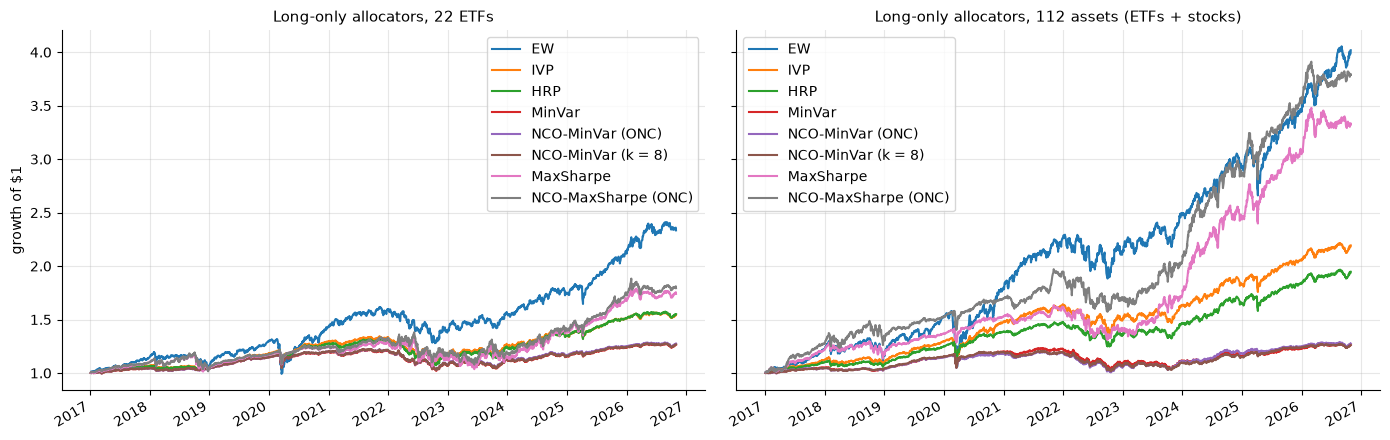

In [6]:
ret_all, w_all, rebal_all, k_all = run_universe(both)
rep_all = report(ret_all, w_all)
print(f"ETFs + stocks: {len(rebal_all)} rebalances; ONC clusters: mean {np.mean(k_all):.1f}, range {min(k_all)}-{max(k_all)}")
print(rep_all.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, r, title in [(axes[0], ret_etf, "22 ETFs"), (axes[1], ret_all, "112 assets (ETFs + stocks)")]:
    (1 + r).cumprod().plot(ax=ax)
    ax.set(title=f"Long-only allocators, {title}", ylabel="growth of $1", xlabel="")
plt.tight_layout(); plt.show()

- Same columns as the ETF table, now on 112 assets. ONC finds 5.4 groups on average (2 to 11).
- The minimum-variance family barely changes from the ETF test (2.4–2.5% return, 5.1–5.2% volatility, about 2 effective holdings): adding 90 stocks does not change which low-risk assets it picks.
- The max-Sharpe family gains the most from the stocks: 13.0% a year for the plain optimizer (Sharpe 1.09) and 14.6% for NCO (1.13). Equal weight returns 15.3% at 15.8% volatility (Sharpe 0.97). These stock-heavy figures carry survivorship bias and are read only as comparisons between allocators.
- NCO's turnover rises sharply with more assets: 0.133 per rebalance against 0.049 for plain minimum variance, and 0.271 against 0.204 for max-Sharpe. After costs NCO-MinVar falls behind (0.426 vs 0.442); NCO-MaxSharpe stays ahead (1.068 vs 1.047).
- The growth chart shows the same picture: equal weight and the two max-Sharpe portfolios end far above the rest ($1 grows to about $3.3 to $4.0), and the three minimum-variance lines overlap almost exactly throughout.
- With more assets, NCO's group labels change more often, and the extra trading cancels the small gain for minimum variance.

### 4.1 · Are the Sharpe differences larger than noise?

Twelve years of daily returns still leave a lot of uncertainty in a Sharpe ratio. Each NCO portfolio is compared with its plain counterpart on the same days. A moving-block bootstrap resamples the daily returns in 21-day blocks (so calm and volatile spells stay together) 2,000 times and recomputes the Sharpe difference each time. This gives a 90% interval for the difference and the share of resamples in which NCO is ahead. A difference is credible only when its 90% interval excludes zero.

In [7]:
def paired_sharpe_diff(a, b, block=21, n_boot=2000, seed=0):
    g = np.random.default_rng(seed)
    x = np.column_stack([a.values, b.values])
    x = x[~np.isnan(x).any(axis=1)]          # drop days where either series is missing
    n = len(x)
    n_blocks = int(np.ceil(n / block))
    sr = lambda m: m.mean(0) / m.std(0) * np.sqrt(252)
    diffs = []
    for _ in range(n_boot):
        starts = g.integers(0, n - block + 1, n_blocks)
        idx = np.concatenate([np.arange(s, s + block) for s in starts])[:n]
        s = sr(x[idx])
        diffs.append(s[0] - s[1])
    diffs = np.array(diffs)
    point = sr(x)
    return {"Sharpe difference": point[0] - point[1], "5%": np.quantile(diffs, 0.05),
            "95%": np.quantile(diffs, 0.95), "P(NCO ahead)": (diffs > 0).mean()}

pairs_bt = [("NCO-MinVar (ONC)", "MinVar"), ("NCO-MinVar (k = 8)", "MinVar"), ("NCO-MaxSharpe (ONC)", "MaxSharpe")]
rows = {}
for uni, r in [("ETFs", ret_etf), ("ETFs + stocks", ret_all)]:
    for a, b in pairs_bt:
        rows[(uni, f"{a} minus {b}")] = paired_sharpe_diff(r[a], r[b])
boot_tab = pd.DataFrame(rows).T
print("Daily-return Sharpe differences (annualised), 21-day block bootstrap, 2,000 resamples")
print(boot_tab.round(3).to_string())

Daily-return Sharpe differences (annualised), 21-day block bootstrap, 2,000 resamples
                                                   Sharpe difference     5%    95%  P(NCO ahead)
ETFs          NCO-MinVar (ONC) minus MinVar                    0.021 -0.029  0.069         0.756
              NCO-MinVar (k = 8) minus MinVar                  0.005 -0.028  0.034         0.576
              NCO-MaxSharpe (ONC) minus MaxSharpe              0.017 -0.043  0.079         0.700
ETFs + stocks NCO-MinVar (ONC) minus MinVar                    0.024 -0.079  0.134         0.638
              NCO-MinVar (k = 8) minus MinVar                 -0.001 -0.105  0.108         0.488
              NCO-MaxSharpe (ONC) minus MaxSharpe              0.028 -0.104  0.166         0.656


- Each row is one NCO portfolio minus its plain counterpart: the Sharpe difference, its 90% interval from 2,000 block resamples, and the share of resamples with NCO ahead.
- ETFs: NCO-MinVar (ONC groups) is ahead by 0.021 (−0.029 to +0.069, ahead in 76% of resamples); with 8 fixed groups by 0.005 (−0.028 to +0.034, 58%); NCO-MaxSharpe by 0.017 (−0.043 to +0.079, 70%).
- ETFs + stocks: NCO-MinVar (ONC) is ahead by 0.024 (−0.079 to +0.134, 64%); with 8 fixed groups behind by 0.001 (−0.105 to +0.108, 49%); NCO-MaxSharpe ahead by 0.028 (−0.104 to +0.166, 66%).
- Every one of the six intervals includes zero, and the intervals are 5 to 10 times wider than the differences. With about ten years of daily returns, none of NCO's gains can be told apart from luck.
- The intervals are wider on 112 assets because the portfolios there are more volatile and differ more from each other day to day, even though the average difference is similar.

## 5 · Risk, concentration and cost

Three views of each allocator in both universes: volatility against Sharpe ratio, effective number of holdings, and average turnover per rebalance.

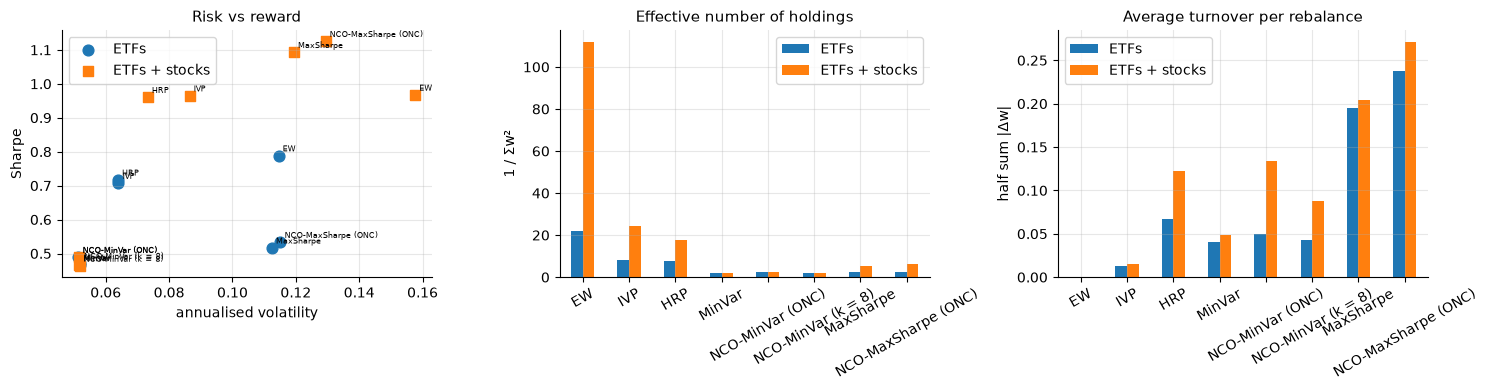

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for rep, mk, lab in [(rep_etf, "o", "ETFs"), (rep_all, "s", "ETFs + stocks")]:
    axes[0].scatter(rep["ann_vol"], rep["sharpe"], marker=mk, s=60, label=lab)
    for n in rep.index:
        axes[0].annotate(n, (rep.loc[n, "ann_vol"], rep.loc[n, "sharpe"]), fontsize=6, xytext=(3, 3), textcoords="offset points")
axes[0].set(title="Risk vs reward", xlabel="annualised volatility", ylabel="Sharpe"); axes[0].legend()
pd.DataFrame({"ETFs": rep_etf["effective N"], "ETFs + stocks": rep_all["effective N"]}).plot.bar(ax=axes[1])
axes[1].set(title="Effective number of holdings", ylabel="1 / Σw²"); axes[1].tick_params(axis="x", rotation=30)
pd.DataFrame({"ETFs": rep_etf["turnover"], "ETFs + stocks": rep_all["turnover"]}).plot.bar(ax=axes[2])
axes[2].set(title="Average turnover per rebalance", ylabel="half sum |Δw|"); axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

- Left: volatility against Sharpe ratio for every allocator, circles for the ETFs and squares for the 112 assets. Middle: effective number of holdings. Right: average turnover per rebalance.
- The minimum-variance family sits at the bottom left in both universes: lowest risk, lowest Sharpe ratio, about 2 effective holdings. Equal weight, inverse variance and HRP sit higher at moderate risk.
- NCO's turnover is above its plain counterpart in every case, and the gap widens with 112 assets (0.133 vs 0.049 for minimum variance). The stability gain from section 3 (a third of the weight change) does not survive on real data, because there the groups are re-estimated each month and their membership changes.

## Conclusions

**What holds**
- With a known covariance and noisy estimates, NCO cuts the excess risk of minimum variance from 22% to 7% and lifts max-Sharpe from 43% to 67% of the best achievable (section 2).
- The reason is visible: NCO solves smaller, more stable problems (error amplification 132 for the full matrix, at most 35 for NCO) and its weights move a third as much when one month is added, as long as the groups stay fixed (section 3).
- A cleaned (denoised) covariance gives nearly the same benefit for minimum variance (8% excess), so grouping and denoising are alternative cures for the same problem (section 2).

**What does not hold on real data**
- In long-only portfolios NCO adds 0.02 to 0.03 to the Sharpe ratio, and all six 90% intervals include zero in both universes (section 4.1).
- NCO trades more than the plain optimizer (0.133 vs 0.049 per rebalance on 112 assets), because its groups change from month to month. After costs, its minimum-variance version falls behind on 112 assets (section 4).
- Simple allocators beat every optimizer on the ETFs: equal weight 0.79, HRP 0.72, inverse variance 0.71, against 0.47 to 0.53 for the optimizers (section 4).
- Minimum-variance portfolios, plain or nested, hold about 2 effective positions, with most of the weight in the calmest assets (section 5).

**How to use it**
1. Use NCO where estimation error is worst: objectives that use expected returns, long-short or leveraged portfolios, and large universes with short histories. That is where the simulated gains were large.
2. For long-only portfolios, the no-short constraint already does most of the protecting; test NCO against inverse variance and HRP before adopting it.
3. Keep the groups stable, for example by refitting them once a year, so that changing labels do not add turnover.
4. Never run minimum variance on a universe that holds a near-cash asset: it will hold almost nothing else.

**Next steps.** Long-short and leveraged versions of the real test, where the simulated gains should show; groups held fixed for a year to cut label-driven turnover; a denoised covariance inside NCO.